In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import tools as tls
import matplotlib.cm as cm
from cosmoblender import qest
from cosmoblender import biases
import camb
import os

def get_camb_clpp(cosmoParams, ells_out):
    #Set up a new set of parameters for CAMB
    #The defaults give one massive neutrino and helium set using BBN consistency
    pars = camb.set_params(H0=cosmoParams['H0'], ombh2=cosmoParams['ombh2'], omch2=cosmoParams['omch2'], mnu=0.06, omk=0, tau=cosmoParams['tau'], As=cosmoParams['As'], ns=cosmoParams['ns'], halofit_version='mead', lmax=3000)

    #calculate results for these parameters
    results = camb.get_results(pars)

    clkk = results.get_lens_potential_cls(lmax=3000)
    ls_ = np.arange(len(clkk[:,0]))
    clpp = clkk[:,0]/((ls_*(ls_+1))**2/2/np.pi)
    return np.interp(ells_out, ls_, clpp)

textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

/var/folders/zf/xwwhf0ps6yx93zy9ttqm3mm80000gn/T/ipykernel_57542/3567291814.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/mpi.py (No module named 'pypar'). Could not load pbs or pypar. MPI will not be used.
IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/shts/__init__.py (No module named 'fsht'). Try running 'python setup.py install' or 'python setup.py build_ext --inplace' from the quicklens directory.


Initialise experiment object

In [5]:
# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = True 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

In [6]:
SO_properties = {'nlev_t': np.array([52., 27., 5.8, 6.3, 15., 37.]),
                 'beam_size':np.array([7.4, 5.1, 2.2, 1.4, 1.0, 0.9]),
                 'freq_GHz': np.array([27.3, 41.7, 93., 143., 225.,278.])}

ACT_properties = {'nlev_t': np.array([15., 15.]),
                 'beam_size':np.array([2.1, 1.4]),
                 'freq_GHz': np.array([90., 150.])}

SO_single_freq_properties = {'nlev_t': np.array([5.8]),
                 'beam_size':np.array([2.2]),
                 'freq_GHz': np.array([143])}

# Initialise experiments with various different mass cuts
SO_single_freq = qest.experiment(lmax = 4000, massCut_Mvir=1e14, **SO_single_freq_properties, **fg_cleaning_dict)
ACT = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

In [7]:
SPT_properties = {'nlev_t': np.array([18.]),
                  'beam_size':np.array([1.]),
                  'freq_GHz': np.array([143.])}

# Initialise experiments with various different mass cuts
SPT_5e15 = qest.experiment(lmax = 3000, massCut_Mvir=5e15, **SPT_properties, **fg_cleaning_dict)

In [8]:
# Choose an experiment
experiment = ACT

One can later inspect the properties by doing

In [9]:
print(experiment)

Mass Cut: 2.00e+14  lmax: 3000  Beam FWHM: [2.1 1.4] Noise (uK arcmin): [15. 15.]  Freq (GHz): [ 90. 150.]


Initialise halo model calculator

In [10]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.075e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

z_max = 5 #3
nZs = 50 #50
nMasses = 50  #30
Mmin = 1e10 #Keep this low -- the 2h term of the bispectrum bias can be sensitive to quite low-mass halos

# Set CIB halo model
cib_model='planck13'#'vierro'

# Initialise a halo model object for the calculation, using mostly default parameters
hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max,  mass_function='tinker', mdef='vir')

ells = np.linspace(2, hm_calc.lmax_out, 50)

In [ ]:
get_secondary_bispec_bias = True
parallelise_secondbispec = False

In [ ]:
# Directory to save to and load cached calculations from
outdir = './cached_calcs/'

# Calculate biases to auto

### Plot as a function of maximum mass


In [ ]:
Mcuts = [1e14, 2e14, 5e14, 1e15]
colors = cm.plasma(np.linspace(0, 1, len(Mcuts)))

which_bias='total'
get_secondary_bispec_bias = True
parallelise_secondbispec = False

exp_list = []
for Mcut in Mcuts:
    print('Working on mass cut: ', np.log10(Mcut))
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=Mcut, **ACT_properties, **fg_cleaning_dict)
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)


    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    
    exp_list.append(experiment)

Working on mass cut:  14.0


Platform 'METAL' is experimental and not all JAX functionality may be correctly supported!
W0000 00:00:1772077160.898201 6851305 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1772077160.957502 6851305 service.cc:145] XLA service 0x36f80f700 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772077160.957523 6851305 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1772077160.958767 6851305 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1772077160.958776 6851305 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Max

systemMemory: 32.00 GB
maxCacheSize: 10.67 GB

Working on mass cut:  14.301029995663981
Working on mass cut:  14.698970004336019
Working on mass cut:  15.0


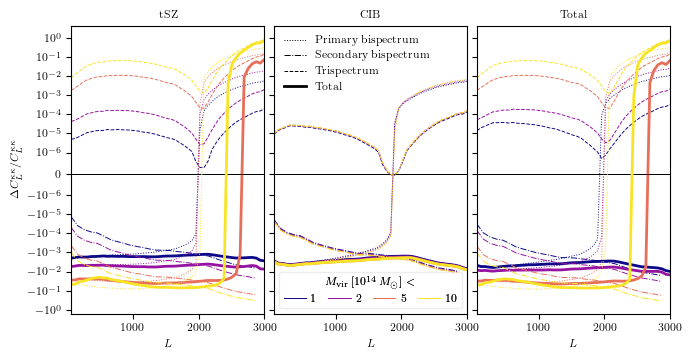

In [ ]:
ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(1.15*textwidth, 1.8*textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}/C_{L}^{\kappa\kappa}$')

for color, experiment, Mcut in zip(colors, exp_list, Mcuts):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        Total_allcouplings = np.zeros(experiment.biases['ells'].shape, dtype='complex128')

        for linestyle, coupling in zip([':','-.', '--', '-'], ['prim_bispec', 'second_bispec', 'trispec', 'Total']):
            if coupling=='second_bispec':
                ells = experiment.biases['second_bispec_bias_ells']
            else:
                ells = experiment.biases['ells']
            Cls = np.interp(ells, experiment.cl_unl.ls, experiment.cl_unl.clpp)

            total = np.zeros(ells.shape, dtype='complex128')
            if coupling != 'Total':
                for term in ['1h', '2h','total']:
                    if term == 'total':
                        axes[j].plot(ells,  total/Cls, color=color, ls=linestyle)
                    
                        if coupling=='second_bispec':
                            Total_allcouplings += np.interp(experiment.biases['ells'], experiment.biases['second_bispec_bias_ells'], total)
                        else:
                            Total_allcouplings += total
                    else:
                        # Extract contribution from this-halo term
                        bias_contribution = experiment.biases[foreground][coupling][term]
                        # Accumulate to later plot the total
                        total += bias_contribution            

                    ax = plt.gca()
                    ax.set_yscale('symlog', linthresh=1e-6)
                    ax.set_xscale('linear')
            else:
                axes[j].plot(ells,  Total_allcouplings/Cls, color=color, ls=linestyle, lw=2)


plt.xlim([60, 3000])
#plt.ylim([-10, 10])

fig.tight_layout()

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.0, wspace=0.05)

# Legend for which coupling
l0 = axes[1].plot([], [], color='k', ls=':')
l1 = axes[1].plot([], [], color='k', ls='-.')
l2 = axes[1].plot([], [], color='k', ls='--')
l3 = axes[1].plot([], [], color='k', ls='-', lw=2)
legend2 = axes[1].legend([l0[0], l1[0], l2[0], l3[0]], [r'Primary bispectrum', r'Secondary bispectrum', r'Trispectrum', r'Total'], fontsize=8, loc='upper left', ncol=1, framealpha=0)
axes[1].add_artist(legend2)

# Another legend for the mass cuts
l0 = axes[1].plot([], [], color=colors[0], ls='-')
l1 = axes[1].plot([], [], color=colors[1], ls='-')
l2 = axes[1].plot([], [], color=colors[2], ls='-')
l3 = axes[1].plot([], [], color=colors[3], ls='-')
legend1 = axes[1].legend([l0[0], l1[0], l2[0], l3[0]], [r'1', r'2', r'5', r'10'], loc='lower center', ncol=4, title=r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', fontsize=8, title_fontsize=8, handletextpad=0.5, columnspacing=1, framealpha=0.2)
axes[1].add_artist(legend1)

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_auto_vs_Mcut.pdf', bbox_inches='tight', dpi=1000)



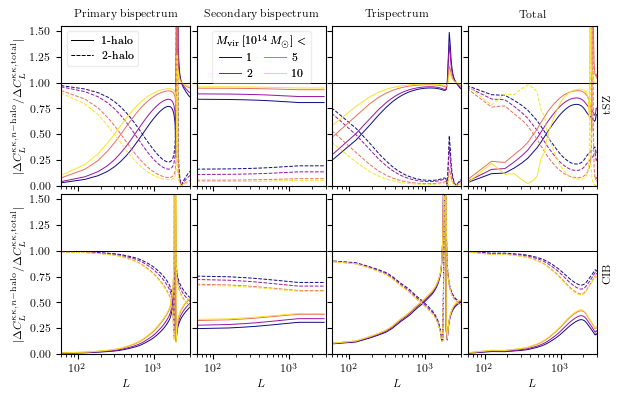

In [ ]:
fig, axes = plt.subplots(2, 4, sharex=True, sharey=True, figsize=(textwidth, 2*textheight), squeeze=True)  

[axes[0,i].set_title(lab) for i, lab, in enumerate([r'Primary bispectrum', r'Secondary bispectrum', r'Trispectrum', r'Total'])]
[axes[-1,j].set_xlabel(r'$L$') for j in range(4)]

[axes[i,0].set_ylabel(lab) for i, lab in enumerate(2*[r'$| \Delta  C_{L}^{\kappa\kappa, n\rm{-halo}}/ \Delta C_{L}^{\kappa\kappa, \rm{total}} | $'])]

 

for row, foreground in enumerate(['tsz', 'cib']):
    for color, experiment, Mcut in zip(colors, exp_list, Mcuts):
        tot_1h = np.zeros(experiment.biases['ells'].shape, dtype='complex128')
        tot_2h = np.zeros(experiment.biases['ells'].shape, dtype='complex128')

        for col, coupling in enumerate(['prim_bispec', 'second_bispec', 'trispec', 'total']):         
            if coupling=='second_bispec':
                ells = experiment.biases['second_bispec_bias_ells']
            else:
                ells = experiment.biases['ells']

            if coupling!='total':
                this_1h = experiment.biases[foreground][coupling]['1h']
                this_2h = experiment.biases[foreground][coupling]['2h']

                if coupling!='second_bispec':
                    tot_1h += this_1h
                    tot_2h += this_2h
                else:
                    tot_1h += np.interp(experiment.biases['ells'], experiment.biases['second_bispec_bias_ells'], this_1h)
                    tot_2h += np.interp(experiment.biases['ells'], experiment.biases['second_bispec_bias_ells'], this_2h)

                axes[row, col].plot(ells,  np.abs(this_1h/(this_1h+this_2h)), color=color, ls='-')
                axes[row, col].plot(ells,  np.abs(this_2h/(this_1h+this_2h)), color=color, ls='--')

            else:
                axes[row, col].plot(ells,  np.abs(tot_1h/(tot_1h+tot_2h)), color=color, ls='-')
                axes[row, col].plot(ells,  np.abs(tot_2h/(tot_1h+tot_2h)), color=color, ls='--')

            ax = plt.gca()
            ax.set_yscale('linear')
            ax.set_xscale('log')
            axes[row, col].axhline(1, color='k', lw=0.5, ls='-')


plt.xlim([60, 3000])
plt.ylim([0., 1.55])

fig.tight_layout()

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, -1]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, -1], [r'tSZ', r'CIB'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.05)

# Legend for which coupling
l0 = axes[0,0].plot([], [], color='k', ls='-')
l1 = axes[0,0].plot([], [], color='k', ls='--')
legend2 = axes[0,0].legend([l0[0], l1[0]], [r'1-halo', r'2-halo'], fontsize=8, loc='upper left', ncol=1, framealpha=0.2)
axes[0,0].add_artist(legend2)

# Another legend for the mass cuts
l0 = axes[0,1].plot([], [], color=colors[0], ls='-')
l1 = axes[0,1].plot([], [], color=colors[1], ls='-')
l2 = axes[0,1].plot([], [], color=colors[2], ls='-')
l3 = axes[0,1].plot([], [], color=colors[3], ls='-')
legend1 = axes[0,1].legend([l0[0], l1[0], l2[0], l3[0]], [r'1', r'2', r'5', r'10'], loc='upper center', ncol=2, title=r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', fontsize=8, title_fontsize=8, handletextpad=0.5, columnspacing=1, framealpha=0.2)
axes[0,1].add_artist(legend1)

plt.savefig(plots_dir+'tsz_cib_whichterm_biases_to_auto.pdf', bbox_inches='tight', dpi=1000)

# Bias as a function of CMB lmax

# Varying all cosmo

In [ ]:
As_array = 2.08e-9 * np.linspace(0.5, 1.5, 4)
H0_array = 68. * np.linspace(0.5, 1.5, 4)
Omega_m_array = 0.31 * np.linspace(0.5, 1.5, 4)

In [237]:
which_bias='total'
exp_list = []

for As in As_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    H0 = 68.
    cosmoParams = {'As':As,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)

    exp_list.append(experiment)

for H0 in H0_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)

    exp_list.append(experiment)

for Omega_m in Omega_m_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    H0 = 68.
    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(Omega_m-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)

    exp_list.append(experiment)


 Takes 116 minutes

In [238]:
signal_Cls = []

for As in As_array:
    H0 = 68.
    cosmoParams = {'As':As,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

    signal_Cls.append(get_camb_clpp(cosmoParams, experiment.biases['ells']))

for H0 in H0_array:
    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

    signal_Cls.append(get_camb_clpp(cosmoParams, experiment.biases['ells']))

for Omega_m in Omega_m_array:
    H0 = 68.
    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(Omega_m-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

    signal_Cls.append(get_camb_clpp(cosmoParams, experiment.biases['ells']))

In [239]:
# Split the lists into three
signal_Cls_perpanel = [signal_Cls[:4], signal_Cls[4:8], signal_Cls[8:]]
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:]]

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

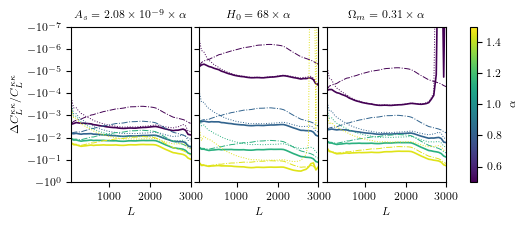

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 0.95, len(As_array)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  
plt.subplots_adjust(hspace=0.05, wspace=0.07)

axes[0].set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}/C_{L}^{\kappa\kappa}$')

plot_breakdown = True
j=0
for signal_Cls_, exp_list_ in zip(signal_Cls_perpanel, exp_list_perpanel):
    axes[j].set_xlabel(r'$L$')
    axes[j].axhline(0, color='k', lw=0.5, ls='-')
    axes[j].set_title([r'$A_s=2.08 \times 10^{-9} \times \alpha$', r'$H_0 = 68 \times \alpha$',r'$\Omega_m = 0.31 \times \alpha$'][j])

    for color, experiment, signal_Cl in zip(colors, exp_list_, signal_Cls_):
        for foreground in ['total']:
            tot_1h = np.zeros(ells.shape, dtype='complex128')
            tot_2h = np.zeros(ells.shape, dtype='complex128')

            for coupling in ['prim_bispec', 'second_bispec', 'trispec', 'total']:         
                if coupling=='second_bispec':
                    ells = experiment.biases['second_bispec_bias_ells']
                else:
                    ells = experiment.biases['ells']

                if coupling!='total':
                    this_1h = experiment.biases[foreground][coupling]['1h']
                    this_2h = experiment.biases[foreground][coupling]['2h']

                    if coupling!='second_bispec':
                        tot_1h += this_1h
                        tot_2h += this_2h
                    else:
                        tot_1h += np.interp(experiment.biases['ells'], experiment.biases['second_bispec_bias_ells'], this_1h)
                        tot_2h += np.interp(experiment.biases['ells'], experiment.biases['second_bispec_bias_ells'], this_2h)
                else:
                    axes[j].plot(ells,  tot_1h/signal_Cl, color=color, ls=':', lw=0.7)
                    axes[j].plot(ells,  tot_2h/signal_Cl, color=color, ls='-.', lw=0.7)
                    axes[j].plot(ells,  (tot_1h+tot_2h)/signal_Cl, color=color, ls='-', lw=1.2)
                
                ax = plt.gca()
                ax.set_yscale('symlog', linthresh=1e-7)
        
    j+=1

#axes[1].legend(title=r'$A_s$ [$\times 10^{-9}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

# Add a colorbar to the right of the plot with these values np.linspace(0.5, 1.5, 4)
import matplotlib as mpl
norm = mpl.colors.Normalize(vmin=0.5, vmax=1.5)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=axes, orientation='vertical', label=r'$\alpha$')



plt.xlim([60, 3000])
plt.ylim([-1e0,-1e-7])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_auto_vs_cosmo.pdf', bbox_inches='tight', dpi=1000)

# Varying all astro

#### Varying Battaglia profile

Note that there's recent evidence that Battaglia does not fit the data except in the limit of the most massive halos. Stay tuned for an implementation of GNFW fit to DESI data.

In [ ]:
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

base_tsz_param_dict = {
    'P0_A0':18.1,
    'P0_alpham':0.154,
    'P0_alphaz':-0.758,
    'xc_A0':0.497,
    'xc_alpham':-0.00865,
    'xc_alphaz':0.731,
    'beta_A0':4.35,
    'beta_alpham':0.0393,
    'beta_alphaz':0.415
    }

exp_list = []

for key, entry in zip(base_tsz_param_dict.keys(), base_tsz_param_dict.values()):
    for tsz_par_scaling in np.linspace(0.5, 1.5, 4):
        filename = outdir+'tsz_dict_with_biases_auto_varyingcosmo_{}_scaling{}'.format(key, tsz_par_scaling)
        if os.path.exists(filename+'.pkl'):
            experiment = qest.load_dict_of_biases(filename+'.pkl')
        else:
            experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

            hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=1e10, nZs=50, nMasses=50, cib_model=cib_model, z_max=2, tsz_param_override={key:entry * tsz_par_scaling})

            hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                        parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)

            experiment.save_biases(output_filename=filename)
            
        exp_list.append(experiment)

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/1.5 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [19]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:12], exp_list[12:16], exp_list[16:20], exp_list[20:24], exp_list[24:28], exp_list[28:32], exp_list[32:]]

signal_Cl = get_camb_clpp(cosmoParams, experiment['ells'])

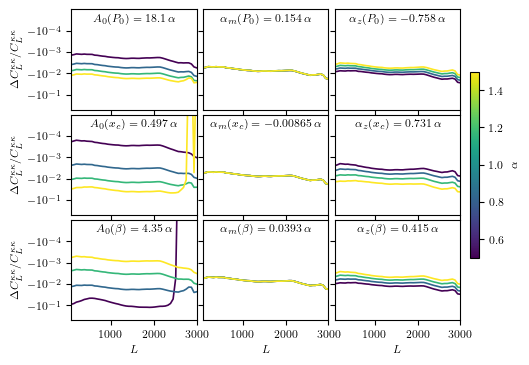

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(np.linspace(0.5, 1.5, 4))))

try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']
scaling = 0.5 * ells*(ells+1)

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
[ax.set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}/C_{L}^{\kappa\kappa}$') for ax in axes[:,0]]

axes = axes.flatten()

titles = [r'$A_0(P_0) = 18.1 \, \alpha$', r'$\alpha_m(P_0) = 0.154 \, \alpha$', r'$\alpha_z(P_0) = -0.758 \, \alpha$',
r'$A_0(x_c) = 0.497 \, \alpha$', r'$\alpha_m(x_c) = -0.00865 \, \alpha$', r'$\alpha_z(x_c) = 0.731 \, \alpha$', 
r'$A_0(\beta) = 4.35 \, \alpha$', r'$\alpha_m(\beta) = 0.0393 \, \alpha$', r'$\alpha_z(\beta) = 0.415 \, \alpha$']

j=0
for exp_list_ in exp_list_perpanel:
    axes[j].axhline(0, color='k', lw=0.5, ls='-')    
    axes[j].text(1500+40, -5e-5, titles[j], ha='center', va='center', fontsize=8, color='k', bbox=dict(facecolor='white', alpha=0))

    for color, experiment in zip(colors, exp_list_):
        try:
            ells = experiment.biases['ells']
        except:
            ells = experiment['ells']
        for foreground in ['tsz']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
                for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                    if coupling=='second_bispec':
                        try:
                            total += np.interp(ells, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                        except:
                            total += np.interp(ells, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                    else:
                        try:
                            total += experiment.biases[foreground][coupling][term]
                        except:
                            total += experiment[foreground][coupling][term]
                    

            axes[j].plot(ells, total/signal_Cl, color=color, lw=1.2)
            axes[j].set_yscale('symlog', linthresh=1e-4)
        
    j+=1

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.05)

# Add a colorbar to the right of the plot with these values np.linspace(0.5, 1.5, 4)
import matplotlib as mpl
norm = mpl.colors.Normalize(vmin=0.5, vmax=1.5)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=axes, orientation='vertical', label=r'$\alpha$', shrink=0.6, pad=0.02)

plt.xlim([60, 3000])
plt.ylim([-5e-1,-1e-5])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'tsz_biases_to_auto_vs_tszparams.pdf', bbox_inches='tight', dpi=1000)

## Varying CIB

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/1.5 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [ ]:
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

base_cib_param_dict = {
    'alpha': 0.36, 
    'beta':1.75,
    'gamma':1.7,
    'delta':3.6,
    'Td_o':24.4,
    'logM_eff':12.6,
    'var':0.5,
    'L_o':8e-8
    }

base_cib_param_error_dict = {
    'alpha': 0.05, 
    'beta':0.06,
    'gamma':0.2,
    'delta':0.2,
    'Td_o':1.9,
    'logM_eff':0.1,
    'var':0.5/10,
    'L_o':8e-8/10
    }

exp_list = []

for key, entry in zip(base_cib_param_dict.keys(), base_cib_param_dict.values()):
    print(key)
    cib_par_ranges = np.arange(-2, 3) * base_cib_param_error_dict[key]
    for cib_par_shift in cib_par_ranges:
        filename = outdir+'cib_dict_with_biases_auto_varyingcib_{}_scaling{}'.format(key, cib_par_shift)
        if os.path.exists(filename+'.pkl'):
            experiment = qest.load_dict_of_biases(filename+'.pkl')
        else:
            experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

            hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=1e9, nZs=50, nMasses=50, cib_model=cib_model, z_max=5)

            # Set the CIB params to the new value
            hm_calc.hcos.cib_params[key] = entry + cib_par_shift

            hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                        parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)

            experiment.save_biases(output_filename=filename)
            
        exp_list.append(experiment)

alpha


2025-02-07 22:18:10.700700: W pjrt_plugin/src/mps_client.cc:534] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!


Metal device set to: Apple M2 Max

systemMemory: 32.00 GB
maxCacheSize: 10.67 GB

beta
gamma
delta
Td_o
logM_eff
var
L_o


In [12]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:5], exp_list[5:10], exp_list[10:15], exp_list[15:20], exp_list[20:25], exp_list[25:30], exp_list[30:35], exp_list[35:40], exp_list[40:]]
signal_Cl = get_camb_clpp(cosmoParams, experiment.biases['ells'])

In [59]:
def moving_average(data, window_size):
    window = np.ones(window_size) / window_size
    return np.convolve(data, window, mode='same')

(-0.1, -0.0005)

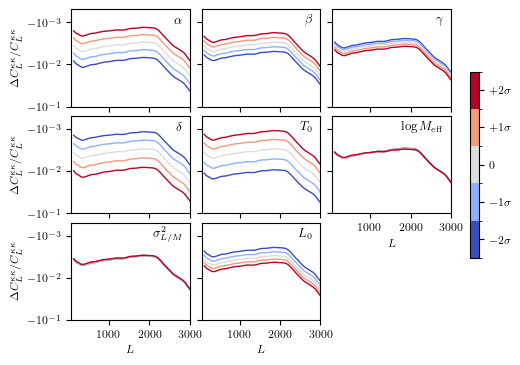

In [ ]:
import matplotlib.cm as cm
import matplotlib as mpl
colors = cm.coolwarm(np.linspace(0, 1, 5))

try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']
scaling = 0.5 * ells*(ells+1)

fig, axes = plt.subplots(3, 3, sharex=False, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
axes[1,2].set_xlabel(r'$L$')
[ax.set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}/C_{L}^{\kappa\kappa}$') for ax in axes[:,0]]

axes = axes.flatten()

titles = [r'$\alpha $', r'$\beta$', r'$\gamma $',
r'$\delta $', r'$T_0 $', r'$\log M_{\rm eff} $', 
r'$\sigma^2_{L/M} $', r'$L_0 $', r'']

j=0
for exp_list_ in exp_list_perpanel:
    axes[j].axhline(0, color='k', lw=0.5, ls='-')  
    axes[j].set_xlim([60, 1000])
    if j not in [5, 6, 7]:
        # Remove tick labels 
        axes[j].set_xticklabels([])

    axes[j].text(2800, -9e-4, titles[j], ha='right', va='center', fontsize=9, color='k', bbox=dict(facecolor='white', alpha=0))

    for color, experiment in zip(colors, exp_list_):
        try:
            ells = experiment.biases['ells']
        except:
            ells = experiment['ells']
        for foreground in ['cib']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
                for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                    if coupling=='second_bispec':
                        try:
                            total += np.interp(ells, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                        except:
                            total += np.interp(ells, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                    else:
                        try:
                            total += experiment.biases[foreground][coupling][term]
                        except:
                            total += experiment[foreground][coupling][term]
                    
            axes[j].plot(ells, moving_average(total/signal_Cl, 2), color=color, lw=1)
            axes[j].set_yscale('symlog', linthresh=1e-4)
            axes[j].set_xlim([60, 3000])
        
    j+=1


# Delete the last subplot
fig.delaxes(axes[-1])

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)

# Define the boundaries for the color intervals
boundaries = np.linspace(0.5, 1.5, 6)  # 6 boundaries will create 5 intervals
# Create a Normalize object with these boundaries
norm = mpl.colors.BoundaryNorm(boundaries, ncolors=256)
# Create the ScalarMappable with the 'coolwarm' colormap and the BoundaryNorm
sm = plt.cm.ScalarMappable(cmap='coolwarm', norm=norm)
sm.set_array([])
# Create the colorbar
cbar = plt.colorbar(sm, ax=axes, orientation='vertical', shrink=0.6, pad=0.04)
# Set the ticks at the center of each color interval
tick_positions = (boundaries[:-1] + boundaries[1:]) / 2
cbar.set_ticks(tick_positions)
# Set the tick labels
cbar.set_ticklabels([r'$-2\sigma$', r'$-1\sigma$', r'$0$', r'$+1\sigma$', r'$+2\sigma$'])


#plt.ylim([-3e-2,-5e-4])
plt.ylim([-0.1,-5e-4])

#plt.savefig(plots_dir+'cib_biases_to_auto_vs_cibparams.pdf', bbox_inches='tight', dpi=1000)

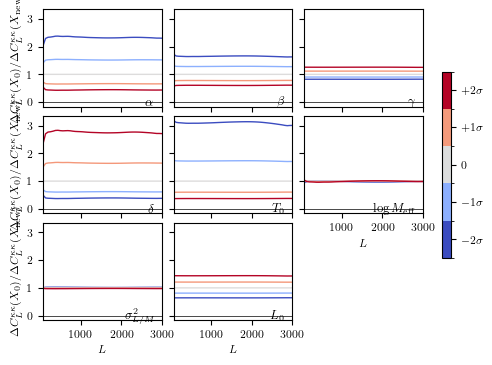

In [ ]:
experiment = exp_list_perpanel[0][2]
try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']
for foreground in ['cib']:            
    reference = np.zeros(ells.shape, dtype='complex128')

    for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
        for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
            if coupling=='second_bispec':
                try:
                    reference += np.interp(ells, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                except:
                    reference += np.interp(ells, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
            else:
                try:
                    reference += experiment.biases[foreground][coupling][term]
                except:
                    reference += experiment[foreground][coupling][term]

import matplotlib.cm as cm
import matplotlib as mpl
colors = cm.coolwarm(np.linspace(0, 1, 5))

try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']
scaling = 0.5 * ells*(ells+1)

fig, axes = plt.subplots(3, 3, sharex=False, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
axes[1,2].set_xlabel(r'$L$')
[ax.set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}(X_0)/\Delta C_{L}^{\kappa\kappa}(X_{\rm{new}})$') for ax in axes[:,0]]

axes = axes.flatten()

titles = [r'$\alpha $', r'$\beta$', r'$\gamma $',
r'$\delta $', r'$T_0 $', r'$\log M_{\rm eff} $', 
r'$\sigma^2_{L/M} $', r'$L_0 $', r'']

j=0
for exp_list_ in exp_list_perpanel:
    axes[j].axhline(0, color='k', lw=0.5, ls='-')  
    axes[j].set_xlim([60, 1000])
    if j not in [5, 6, 7]:
        # Remove tick labels 
        axes[j].set_xticklabels([])

    axes[j].text(2800, -9e-4, titles[j], ha='right', va='center', fontsize=9, color='k', bbox=dict(facecolor='white', alpha=0))

    for color, experiment in zip(colors, exp_list_):
        try:
            ells = experiment.biases['ells']
        except:
            ells = experiment['ells']
        for foreground in ['cib']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
                for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                    if coupling=='second_bispec':
                        try:
                            total += np.interp(ells, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                        except:
                            total += np.interp(ells, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                    else:
                        try:
                            total += experiment.biases[foreground][coupling][term]
                        except:
                            total += experiment[foreground][coupling][term]
                    
            axes[j].plot(ells, moving_average(total/reference, 2), color=color, lw=1)
            axes[j].set_yscale('linear')
            axes[j].set_xlim([60, 3000])
        
    j+=1


# Delete the last subplot
fig.delaxes(axes[-1])

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)

# Define the boundaries for the color intervals
boundaries = np.linspace(0.5, 1.5, 6)  # 6 boundaries will create 5 intervals
# Create a Normalize object with these boundaries
norm = mpl.colors.BoundaryNorm(boundaries, ncolors=256)
# Create the ScalarMappable with the 'coolwarm' colormap and the BoundaryNorm
sm = plt.cm.ScalarMappable(cmap='coolwarm', norm=norm)
sm.set_array([])
# Create the colorbar
cbar = plt.colorbar(sm, ax=axes, orientation='vertical', shrink=0.6, pad=0.04)
# Set the ticks at the center of each color interval
tick_positions = (boundaries[:-1] + boundaries[1:]) / 2
cbar.set_ticks(tick_positions)
# Set the tick labels
cbar.set_ticklabels([r'$-2\sigma$', r'$-1\sigma$', r'$0$', r'$+1\sigma$', r'$+2\sigma$'])


#plt.ylim([-3e-2,-5e-4])
#plt.ylim([-0.1,-5e-4])

#plt.savefig(plots_dir+'cib_biases_to_auto_vs_cibparams.pdf', bbox_inches='tight', dpi=1000)

# With fg cleaning

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [ ]:
SO_properties = {'nlev_t': np.array([52., 27., 5.8, 6.3, 15., 37.]),
                 'beam_size':np.array([7.4, 5.1, 2.2, 1.4, 1.0, 0.9]),
                 'freq_GHz': np.array([27.3, 41.7, 93., 143., 225.,278.])}

H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

lmaxes = np.linspace(3000, 4500, 4).astype(int)

get_secondary_bispec_bias = True
parallelise_secondbispec = False

exp_list = []

for MV_ILC_bool, deproject_CIB, deproject_tSZ, label in zip([True, False, False], [False, True, False], [False, False, True], [r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC']):
    fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}
    for lmax in lmaxes:
        print(lmax)
        filename = outdir+'dict_with_biases_auto_fgcleaning_{}_lmax{}'.format(label, lmax)
        if os.path.exists(filename+'.pkl'):
            experiment = qest.load_dict_of_biases(filename+'.pkl')
        else:
            experiment = qest.experiment(lmax = lmax, massCut_Mvir=2e14, **SO_properties, **fg_cleaning_dict)
        
            for which_bias in ['tsz', 'cib', 'mixed']:
                hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

                if which_bias=='total' or which_bias=='tsz':
                    hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
                if which_bias=='total' or which_bias=='cib':
                    hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                            parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
                if which_bias=='total' or which_bias=='mixed':
                    hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
        
            experiment.save_biases(output_filename=filename)
            
        exp_list.append(experiment)

3000
3500
4000
4500
3000
3500
4000
4500
3000
3500
4000
4500


In [15]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:12], exp_list[12:16], exp_list[16:20], exp_list[20:24], exp_list[24:28], exp_list[28:32], exp_list[32:]]

signal_Cl = get_camb_clpp(cosmoParams, experiment['ells'])

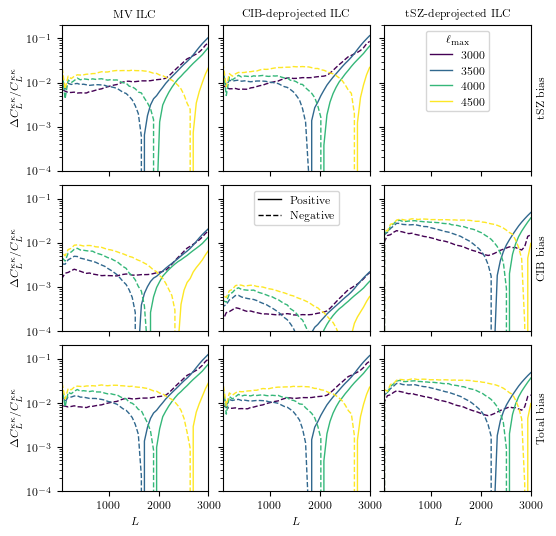

In [ ]:
try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']

import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(lmaxes)))

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
[ax.set_ylabel(r'$\Delta C_{L}^{\kappa\kappa}/C_{L}^{\kappa\kappa}$') for ax in axes[:,0]]
[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'MV ILC', r'CIB-deprojected ILC', r'tSZ-deprojected ILC'])]

# Replace the colorbar with a legend to go in the third subplot
[axes[0,2].plot([],[], color=colors[i], lw=1, label=lmaxes.astype(int).astype(str)[i]) for i in range(len(lmaxes))]
axes[0,2].legend(title=r'$\ell_{\rm max}$', fontsize=8, title_fontsize=8, loc='upper center', ncols=1)

# Replace the colorbar with a legend to go in the fifth subplot
axes[1,1].plot([],[], color='k', lw=1, ls='-', label=r'Positive')
axes[1,1].plot([],[], color='k', lw=1, ls='--', label=r'Negative')
axes[1,1].legend(fontsize=8, title_fontsize=8, loc='upper center', ncols=1)

plot_breakdown = False

for exp_list_, fgcl_label, col in zip(exp_list_perpanel, 3*[r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC'], 3*[0,1,2]): 
    for row, foreground in zip([0,1,2], ['tsz', 'cib', 'total']):
        axes[row,col].axhline(0, color='k', lw=0.5, ls='-')   
        for color, experiment in zip(colors, exp_list_):
            total = np.zeros(ells.shape, dtype='complex128')

            for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
                for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                    if coupling=='second_bispec':
                        try:
                            total += np.interp(ells, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                        except:
                            total += np.interp(ells, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                    else:
                        try:
                            total += experiment.biases[foreground][coupling][term]
                        except:
                            total += experiment[foreground][coupling][term]
            axes[row,col].plot(ells, total/signal_Cl, color=color, ls='-', label=None, lw=1.)
            axes[row,col].plot(ells, -total/signal_Cl, color=color, ls='--', label=None, lw=1.)            

            ax = plt.gca()
            ax.set_yscale('log')
            

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'tSZ bias', r'CIB bias', r'Total bias'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)


plt.xlim([60, 3000])
plt.ylim([1e-4,0.2])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'all_biases_to_auto_vs_fgcleaning_and_lmax.pdf', bbox_inches='tight', dpi=1000)